In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error, accuracy_score
from sklearn.tree import DecisionTreeClassifier, plot_tree

In [3]:
study_hours = np.array([1, 2, 3, 4, 5])
scores = np.array([52, 58, 65, 72, 79])
model = LinearRegression()

In [4]:
X = study_hours.reshape(-1, 1)
y = scores

model.fit(X, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[6.8]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,44.8
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[3.16]


In [5]:
prediction = model.predict([[int(input("Enter the study hours: "))]])
print(prediction // 1)
print(f"Slope: {model.coef_[0]}")
print(f"Intercept: {model.intercept_}")

[72.]
Slope: 6.800000000000001
Intercept: 44.8


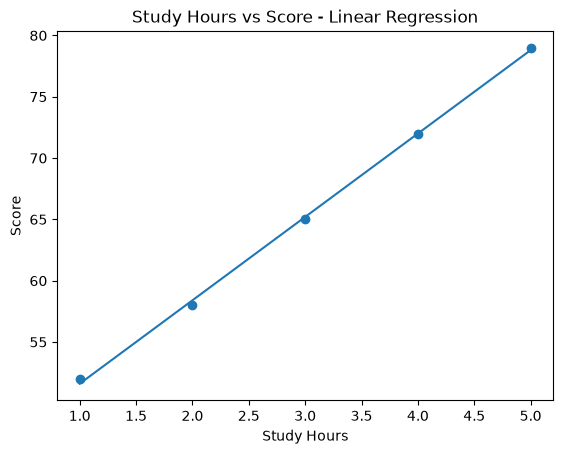

In [6]:
plt.scatter(study_hours, scores)
plt.plot(study_hours, model.predict(X))

plt.xlabel("Study Hours")
plt.ylabel("Score")
plt.title("Study Hours vs Score - Linear Regression")

plt.show()

In [7]:
df = pd.read_csv(r"C:\Users\Admin\.vscode\csv\linear_regression_student_dataset.csv")
print(df.head())
print(df.tail())
print(df.shape)
print(df.dtypes)
print(df.info())

   Student_ID  Study_Hours  Attendance_Percent  Previous_Score  Exam_Score
0           1          8.0                96.3            78.9       100.0
1           2          4.9                88.0            88.6        99.5
2           3          8.7                70.6            65.0       100.0
3           4          7.3                98.8            47.2        99.8
4           5          1.8                91.2            40.7        77.5
    Student_ID  Study_Hours  Attendance_Percent  Previous_Score  Exam_Score
95          96          6.7                67.2            85.1        95.5
96          97          4.3                84.0            89.0        88.5
97          98          1.8                95.0            80.1        80.9
98          99          2.1                67.9            79.0        81.3
99         100          9.7                72.4            72.1       100.0
(100, 5)
Student_ID              int64
Study_Hours           float64
Attendance_Percent    flo

In [8]:
X = df[["Study_Hours"]]
y = df["Exam_Score"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.2, random_state = 42
)
print(f"Traning data: {X_train.shape}")
print(f"Testing data: {X_test.shape}")

Traning data: (80, 1)
Testing data: (20, 1)


In [9]:
model = LinearRegression()
model.fit(X_train, y_train)
predictions = model.predict(X_test)
for i in y_test.values, predictions:
    print(i)
#print(results)

[ 79.4  96.9  66.6 100.  100.   87.9 100.   96.2  81.3 100.  100.   97.7
  89.6  86.3  96.8  77.5  79.5 100.   99.8 100. ]
[ 81.45011042  94.87974459  82.64385568  98.46098036  99.35628931
  94.87974459 102.93752509  94.87974459  86.82196409  97.86410773
  99.05785299  96.96879879  83.24072831  86.82196409  81.15167411
  79.36105622  84.73290988  94.87974459  94.28287196 102.93752509]


In [10]:
r2 = r2_score(y_test, predictions)
print(f"r2: {r2}")

r2: 0.6165752304242151


In [11]:
mse = mean_squared_error(y_test, predictions)
print(f"MSE: {mse}")

MSE: 37.287627488379314


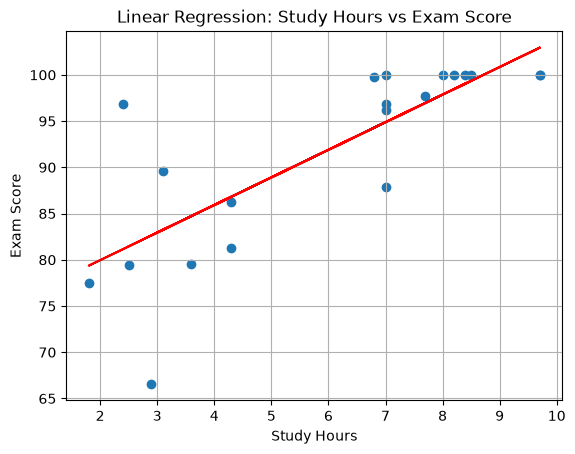

In [12]:
plt.scatter(X_test, y_test)
plt.plot(X_test, predictions, c="r")
plt.xlabel("Study Hours")
plt.ylabel("Exam Score")
plt.grid()
plt.title("Linear Regression: Study Hours vs Exam Score")
plt.show()

In [13]:
new_student = pd.DataFrame({"Study_Hours": [7]})
prediction = model.predict(new_student)
print(f"Predicted score: {int(prediction[0])}")

Predicted score: 94


In [22]:
df["Result"] = df["Exam_Score"].apply(lambda score: "Pass" if score >= 75 else "Fail")
print("\nResult column:")
print(f"{df[["Exam_Score", "Result"]]}")


Result column:
    Exam_Score Result
0        100.0   Pass
1         99.5   Pass
2        100.0   Pass
3         99.8   Pass
4         77.5   Pass
..         ...    ...
95        95.5   Pass
96        88.5   Pass
97        80.9   Pass
98        81.3   Pass
99       100.0   Pass

[100 rows x 2 columns]


In [15]:
X = df[["Study_Hours", "Attendance_Percent", "Previous_Score"]]
y = df["Result"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)
print(f"\nTraining data: {X_train.shape}")
print(f"Testing data: {y_test.shape}")


Training data: (80, 3)
Testing data: (20,)


In [ ]:
model = DecisionTreeClassifier(max_depth = 2, random_state = 42)
model.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",4
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at 

In [17]:
predictions = model.predict(X_test)
print("\nPredictions:")
print(predictions)
results = pd.DataFrame({"Actual": y_test.values, "Predicted": predictions})
print("\nActual vs Predicted:")
print(results)


Predictions:
['Fail' 'Distinction' 'Fail' 'Distinction' 'Distinction' 'Distinction'
 'Distinction' 'Distinction' 'Distinction' 'Distinction' 'Distinction'
 'Distinction' 'Distinction' 'Distinction' 'Distinction' 'Fail'
 'Distinction' 'Distinction' 'Distinction' 'Distinction']

Actual vs Predicted:
         Actual    Predicted
0   Distinction         Fail
1   Distinction  Distinction
2          Fail         Fail
3   Distinction  Distinction
4   Distinction  Distinction
5   Distinction  Distinction
6   Distinction  Distinction
7   Distinction  Distinction
8   Distinction  Distinction
9   Distinction  Distinction
10  Distinction  Distinction
11  Distinction  Distinction
12  Distinction  Distinction
13  Distinction  Distinction
14  Distinction  Distinction
15  Distinction         Fail
16  Distinction  Distinction
17  Distinction  Distinction
18  Distinction  Distinction
19  Distinction  Distinction


In [18]:
accuracy = accuracy_score(y_test, predictions)
print(f"\nAccuracy: {accuracy}")
print(f"Accuracy percentage: {accuracy * 100} %")


Accuracy: 0.9
Accuracy percentage: 90.0 %


In [28]:
<html>
    <head>
        <title>Hi</title>
    </head>
</html>

SyntaxError: invalid syntax (67536876.py, line 1)

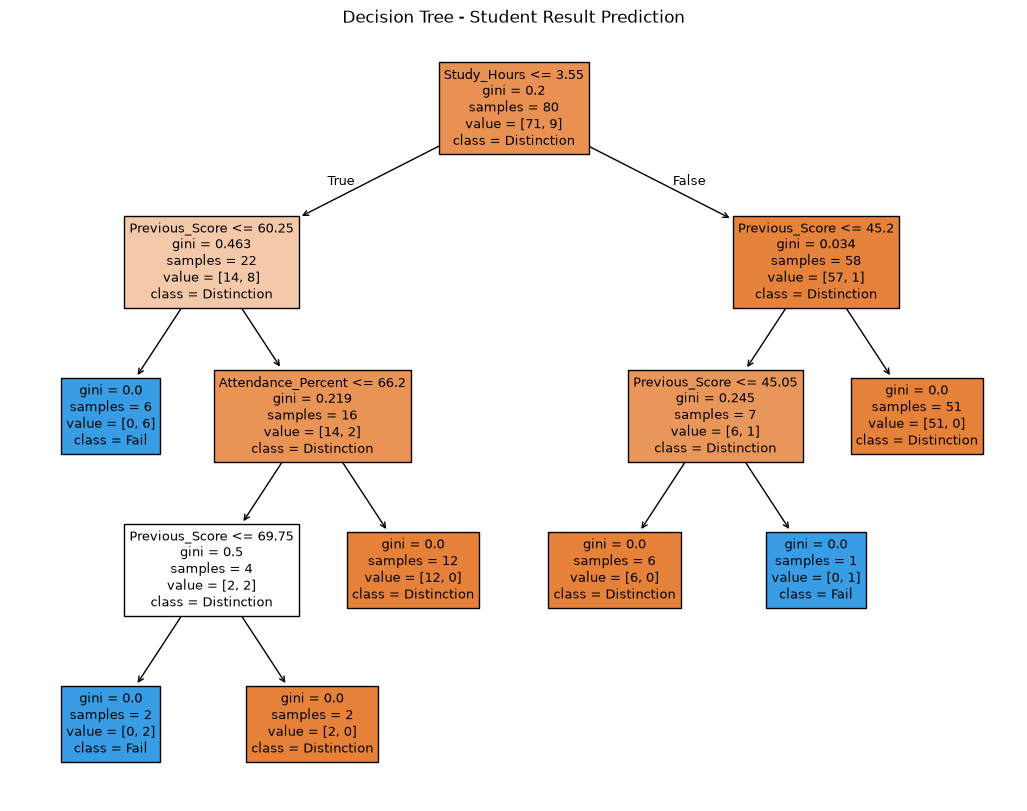

In [27]:
plt.figure(figsize = (13, 10))
plot_tree(model, feature_names = X.columns, class_names = model.classes_, filled = True)
plt.title("Decision Tree - Student Result Prediction")
plt.show()

In [ ]:
new_student = pd.DataFrame({
    "Study_Hours": [3],
    "Attendance_Percent": [8],
    "Previous_Score": [73]
})
new_prediction = model.predict(new_student)
print("\nNew Student Prediction:")
print(new_prediction)


New Student Prediction:
['Distinction']
